# M04-L02 — Treinamento, Validação, Teste, Perda e Regularização

## Laboratório

**Antes de começar:**

1. Abra este notebook no Google Colab.
2. No menu, escolha **Arquivo → Salvar uma cópia no Drive**.
3. Execute as células na ordem.
4. O **código de treinamento** é fornecido pronto, mas nas variações de arquitetura você vai **construir as próprias redes**, usando a MLP simples como exemplo.

Nesta versão do laboratório, você vai trabalhar com três arquiteturas sobre os mesmos dados:

- **simples:** `5 → 8 → 3` — já fornecida, como na M04-L01;
- **mais larga:** `5 → 16 → 3` — você deverá construí-la modificando a rede de exemplo;
- **mais profunda:** `5 → 16 → 8 → 3` — você deverá construí-la adicionando uma nova camada escondida.

A ideia não é escrever o laço de treinamento do zero. O foco é entender **o que precisa mudar na arquitetura** e depois observar como essa mudança afeta o treinamento.

Ao final, a melhor arquitetura será escolhida **somente pelos resultados de validação** e então retreinada com regularização. O conjunto de teste continua reservado para a avaliação final.


## Parte 0 — Retomada rápida da M04-L01

Antes de treinar, precisamos religar exatamente onde a M04-L01 parou: a tabela `df_features_tensores.pt`, convertida em tensores, e a classe `ClassificadorIrisMLP` com 5 entradas, 8 neurônios escondidos e 3 saídas.


In [1]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(42)


**IMPORTANTE**: Ao executar a célula de código abaixo, será pedido a permissão para o colab acessar o seu Google Drive. É necessário que você permita para ele salvar ou recuperar arquivos que poderão ser usados nesta ou em lições futuras.

In [2]:
import os
import torch  # Adicionado para poder carregar o arquivo .pt
from google.colab import drive

# 1. Conecta o Google Drive do aluno
drive.mount('/content/drive')

# 2. Caminho do ARQUIVO salvo na lição anterior
caminho_do_arquivo = '/content/drive/MyDrive/dados_modulo_04/df_features_tensores.pt'

# 3. Validação para garantir que o aluno fez a lição anterior
if os.path.exists(caminho_do_arquivo):
    print("Arquivo localizado com sucesso! Carregando os dados")

    # 4. Carrega o tensor para a variável df_features_tensores
    df_features_tensores = torch.load(caminho_do_arquivo, weights_only=False)
    print("Pronto para iniciar a lição!")

else:
    print("Atenção: O arquivo não foi encontrado no seu Google Drive.")
    print("Certifique-se de que você executou o código de salvamento no final da lição anterior!")

# Como agora df_features é um Tensor do PyTorch, o .head() não funciona (ele é exclusivo do Pandas).
# Para mostrar as primeiras linhas de um tensor, usamos a fatiamento do Python (ex: as primeiras 5 linhas):
df_features_tensores[:5]


Mounted at /content/drive
Arquivo localizado com sucesso! Carregando os dados
Pronto para iniciar a lição!


,media_r,media_g,media_b,std_cinza,prop_segmentada,classe
0,0.418250,0.463520,0.320472,0.180413,0.480365,iris_setosa.jpg
1,0.422511,0.438256,0.310805,0.170654,0.480242,iris_setosa.jpg
2,0.424551,0.456770,0.315956,0.162451,0.484216,iris_setosa.jpg
3,0.422578,0.460586,0.308054,0.168153,0.489187,iris_setosa.jpg
4,0.435096,0.457318,0.310482,0.185856,0.469266,iris_setosa.jpg


In [3]:
# Separando entradas (X) e rótulo (y), exatamente como na M04-L01
colunas_features = ["media_r", "media_g", "media_b", "std_cinza", "prop_segmentada"]

X = df_features_tensores[colunas_features].values
y = df_features_tensores["classe"].astype("category").cat.codes.values

X_tensor = torch.tensor(X, dtype=torch.float32)
y_tensor = torch.tensor(y, dtype=torch.long)

print("Formato de X_tensor:", X_tensor.shape)
print("Formato de y_tensor:", y_tensor.shape)


Formato de X_tensor: torch.Size([64, 5])
Formato de y_tensor: torch.Size([64])


In [4]:
# Arquitetura simples: a mesma referência da M04-L01
class ClassificadorIrisMLP(nn.Module):
    def __init__(self, n_entrada=5, n_escondida=8, n_saida=3):
        super().__init__()
        self.camada1 = nn.Linear(n_entrada, n_escondida)
        self.ativacao = nn.ReLU()
        self.camada2 = nn.Linear(n_escondida, n_saida)

    def forward(self, x):
        x = self.camada1(x)
        x = self.ativacao(x)
        x = self.camada2(x)
        return x

modelo = ClassificadorIrisMLP()
print(modelo)


ClassificadorIrisMLP(
  (camada1): Linear(in_features=5, out_features=8, bias=True)
  (ativacao): ReLU()
  (camada2): Linear(in_features=8, out_features=3, bias=True)
)


### Diagrama da arquitetura simples

O diagrama abaixo torna explícito o caminho que cada amostra percorre: **5 valores de entrada → 8 neurônios escondidos com ReLU → 3 valores de saída**. Cada linha representa uma conexão aprendida durante o treinamento.


![Diagrama da MLP simples 5-8-3](https://drive.google.com/thumbnail?id=1aEQcm_ZSUq1mbkExPrkv4LCR1kdbm5pP&sz=w1600)

In [5]:
# Retomando a predição não treinada: ainda é um chute, pois os pesos são aleatórios
with torch.no_grad():
    predicao_inicial = modelo(X_tensor[:5])
print(predicao_inicial)


tensor([[ 0.1985, -0.2199, -0.1144],
        [ 0.1991, -0.2190, -0.1134],
        [ 0.1968, -0.2206, -0.1151],
        [ 0.1969, -0.2209, -0.1174],
        [ 0.2017, -0.2167, -0.1093]])


## Exemplo guiado 1 — Função de Perda

Vamos dar um número concreto para aquele "chute" da M04-L01. Instanciamos a função de perda e calculamos o valor dela sobre um pequeno lote de dados.


In [6]:
criterio = nn.CrossEntropyLoss()

# Sorteamos um pequeno lote para não depender da ordem das linhas no CSV
torch.manual_seed(42)
indices_exemplo = torch.randperm(len(X_tensor))[:16]
X_lote_exemplo = X_tensor[indices_exemplo]
y_lote_exemplo = y_tensor[indices_exemplo]

saida_modelo = modelo(X_lote_exemplo)
perda_exemplo = criterio(saida_modelo, y_lote_exemplo)

print("Perda do modelo ainda não treinado:", round(perda_exemplo.item(), 4))


Perda do modelo ainda não treinado: 1.1418


Para três classes, `ln(3) ≈ 1,10` é uma referência para predições aproximadamente uniformes. A perda inicial pode ficar acima ou abaixo disso porque os pesos são aleatórios e o lote também influencia o valor. O ponto importante aqui é: **nenhum peso foi ajustado a partir dos dados ainda**.


In [7]:
indices_lote_2 = torch.randperm(len(X_tensor))[16:32]
X_lote_2 = X_tensor[indices_lote_2]
y_lote_2 = y_tensor[indices_lote_2]

saida_modelo_2 = modelo(X_lote_2)
perda_lote_2 = criterio(saida_modelo_2, y_lote_2)

print("Perda do lote de exemplo:", round(perda_exemplo.item(), 4))
print("Perda do segundo lote:    ", round(perda_lote_2.item(), 4))


Perda do lote de exemplo: 1.1418
Perda do segundo lote:     1.0712


### Atividade conceitual A — interpretando a perda

Observe os dois valores calculados acima.

**Responda em texto:**

1. Qual lote apresentou a menor perda?
2. Por que uma perda menor indica que, naquele lote, as saídas da rede estavam mais compatíveis com os rótulos verdadeiros?
3. Por que comparar apenas dois lotes ainda não é suficiente para escolher uma arquitetura?

*Sua resposta:*

- O segundo lote apresentou menor perda
- Porque quanto menor o valor da perda, pode-se dizer que mais próximas estão as probabilidades calculadas das classes verdadeiras.
- Não é suficiente pois a perda de lotes isolados pode sofrer muita influência de amostras aleatórias que caíram lá por um sorteio, além do modelo nem ter sido treinado ainda.


## Exemplo guiado 2 — Um único passo de otimização

Agora vamos dar o primeiro passo real de ajuste nos pesos. O objetivo desta célula não é treinar a rede inteira, mas mostrar que `zero_grad() → backward() → step()` realmente altera um parâmetro.


In [8]:
# torch.optim.SGD: Geralmente leva a uma melhor generalização e maior acurácia final
otimizador = torch.optim.SGD(modelo.parameters(), lr=0.01)

peso_antes = modelo.camada1.weight[0, 0].item()
print("Peso antes do passo:", peso_antes)

otimizador.zero_grad()
saida = modelo(X_lote_exemplo)
perda = criterio(saida, y_lote_exemplo)
perda.backward()
otimizador.step()

peso_depois = modelo.camada1.weight[0, 0].item()
print("Peso depois do passo:", peso_depois)
print("Mudança observada:", peso_depois - peso_antes)


Peso antes do passo: 0.34191203117370605
Peso depois do passo: 0.34187474846839905
Mudança observada: -3.7282705307006836e-05


### Atividade conceitual B — interpretando o passo de otimização

1. O peso aumentou ou diminuiu?
2. A mudança foi grande ou pequena?
3. Como a taxa de aprendizado (`lr=0.01`) se relaciona com o tamanho desses passos?

*Sua resposta:*

- O peso diminuiu.
- A mudança foi bem pequena.
- Ela atua como um fator de escala que multiplica o gradiente no momento de atualizar os parâmetros.


## Exemplo guiado 3 — Treino, validação e teste

Agora separamos os dados em **três partições**. Treino ajusta os pesos, validação permite comparar decisões e arquiteturas, e teste fica intocado até o final.


In [9]:
# Primeira divisão: separa treino do restante (validação + teste)
X_treino, X_resto, y_treino, y_resto = train_test_split(
    X_tensor, y_tensor, test_size=0.30, stratify=y_tensor, random_state=42
)

# Segunda divisão: separa o restante em validação e teste, em partes iguais
X_val, X_teste, y_val, y_teste = train_test_split(
    X_resto, y_resto, test_size=0.50, stratify=y_resto, random_state=42
)

print("Treino:   ", X_treino.shape[0], "amostras")
print("Validação:", X_val.shape[0], "amostras")
print("Teste:    ", X_teste.shape[0], "amostras")


Treino:    44 amostras
Validação: 10 amostras
Teste:     10 amostras


In [10]:
dataset_treino = TensorDataset(X_treino, y_treino)
dataset_val = TensorDataset(X_val, y_val)
dataset_teste = TensorDataset(X_teste, y_teste)

loader_treino = DataLoader(dataset_treino, batch_size=8, shuffle=True)
loader_val = DataLoader(dataset_val, batch_size=8, shuffle=False)
loader_teste = DataLoader(dataset_teste, batch_size=8, shuffle=False)


### Função de treinamento que será reaproveitada

Para que a comparação entre arquiteturas seja justa, todas elas usarão **a mesma função de treinamento**, o mesmo número de épocas, o mesmo `lr`, as mesmas partições e a mesma semente. Assim, a principal diferença entre os experimentos será a arquitetura.


In [11]:
def treinar_modelo(
    modelo,
    loader_treino,
    loader_val,
    numero_de_epocas=60,
    lr=0.01,
    weight_decay=0.0
):
    criterio = nn.CrossEntropyLoss()

    otimizador = torch.optim.Adam(
        modelo.parameters(),
        lr=lr,
        weight_decay=weight_decay
    )

    historico = {
        "perda_treino": [],
        "perda_val": [],
        "acc_treino": [],
        "acc_val": []
    }

    for epoca in range(numero_de_epocas):

        # =====================
        # TREINO
        # =====================
        modelo.train()

        soma_perda_treino = 0.0
        acertos_treino = 0
        total_treino = 0

        for X_lote, y_lote in loader_treino:
            otimizador.zero_grad()

            saida = modelo(X_lote)
            perda = criterio(saida, y_lote)

            perda.backward()
            otimizador.step()

            tamanho_lote = y_lote.size(0)

            soma_perda_treino += perda.item() * tamanho_lote

            predicoes = torch.argmax(saida, dim=1)
            acertos_treino += (predicoes == y_lote).sum().item()
            total_treino += tamanho_lote

        perda_treino = soma_perda_treino / total_treino
        acc_treino = acertos_treino / total_treino

        # =====================
        # VALIDAÇÃO
        # =====================
        modelo.eval()

        soma_perda_val = 0.0
        acertos_val = 0
        total_val = 0

        with torch.no_grad():
            for X_lote, y_lote in loader_val:
                saida = modelo(X_lote)
                perda = criterio(saida, y_lote)

                tamanho_lote = y_lote.size(0)

                soma_perda_val += perda.item() * tamanho_lote

                predicoes = torch.argmax(saida, dim=1)
                acertos_val += (predicoes == y_lote).sum().item()
                total_val += tamanho_lote

        perda_val = soma_perda_val / total_val
        acc_val = acertos_val / total_val

        # =====================
        # HISTÓRICO
        # =====================
        historico["perda_treino"].append(perda_treino)
        historico["perda_val"].append(perda_val)
        historico["acc_treino"].append(acc_treino)
        historico["acc_val"].append(acc_val)

    return historico


def mostrar_resumo(historico, nome):
    print(nome)
    print(
        "  Perda final de treino:     ",
        round(historico["perda_treino"][-1], 4)
    )
    print(
        "  Perda final de validação:  ",
        round(historico["perda_val"][-1], 4)
    )
    print(
        "  Acurácia final de treino:  ",
        round(historico["acc_treino"][-1], 4)
    )
    print(
        "  Acurácia final de validação:",
        round(historico["acc_val"][-1], 4)
    )

## Exercício de treinamento 1 — Arquitetura simples (`5 → 8 → 3`)

Este é o primeiro treinamento completo. O código já está pronto: execute e interprete as curvas. Ele será a referência para os dois experimentos seguintes.


In [12]:
torch.manual_seed(42)
modelo_simples = ClassificadorIrisMLP()
historico_simples = treinar_modelo(
    modelo_simples, loader_treino, loader_val,
    numero_de_epocas=60, lr=0.01
)

mostrar_resumo(historico_simples, "Arquitetura simples (5 → 8 → 3)")


Arquitetura simples (5 → 8 → 3)
  Perda final de treino:      0.328
  Perda final de validação:   0.3197
  Acurácia final de treino:   1.0
  Acurácia final de validação: 1.0


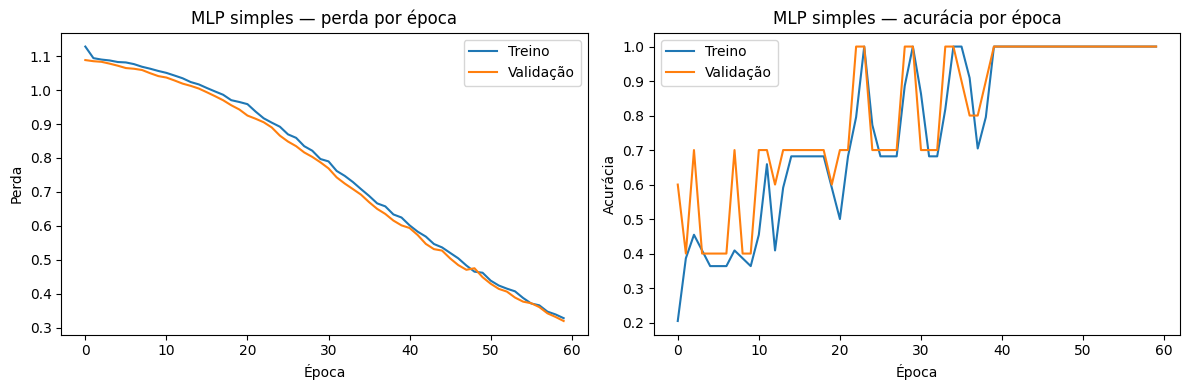

In [13]:
fig, eixos = plt.subplots(1, 2, figsize=(12, 4))

eixos[0].plot(historico_simples["perda_treino"], label="Treino")
eixos[0].plot(historico_simples["perda_val"], label="Validação")
eixos[0].set_title("MLP simples — perda por época")
eixos[0].set_xlabel("Época")
eixos[0].set_ylabel("Perda")
eixos[0].legend()

eixos[1].plot(historico_simples["acc_treino"], label="Treino")
eixos[1].plot(historico_simples["acc_val"], label="Validação")
eixos[1].set_title("MLP simples — acurácia por época")
eixos[1].set_xlabel("Época")
eixos[1].set_ylabel("Acurácia")
eixos[1].legend()

plt.tight_layout()
plt.show()


**Responda em texto:**

1. A rede simples parece aprender o conjunto de treino?
2. Treino e validação evoluem de forma parecida ou começam a se afastar?
3. Há sinais de underfitting, overfitting ou nenhum dos dois de forma clara? Justifique pelas curvas.

*Sua resposta:*

- Sim, a rede parece aprender o conjunto de treino.
- Eles evoluem de forma parecida
- Não há sinais de underfitting ou overfitting. A acurácia e a perda acompanham o bom desempenho do treino, o modelo generalizou bem para os dados não vistos sem indícios de memorização excessiva ou falta de aprendizado.


## Largura e profundidade da rede

Agora vamos mudar **uma coisa de cada vez**.

- **Largura** = quantidade de neurônios em uma camada escondida. Passar de `8` para `16` neurônios torna a rede mais larga.
- **Profundidade** = quantidade de camadas escondidas. Passar de uma camada escondida para duas torna a rede mais profunda.

Aumentar largura ou profundidade aumenta a **capacidade** da rede: ela ganha mais parâmetros e mais possibilidades para representar padrões. Isso pode melhorar o aprendizado, mas também pode aumentar o risco de **overfitting** quando os dados são poucos.


![Comparação entre MLP simples, mais larga e mais profunda](https://drive.google.com/thumbnail?id=1azh6IbjqgRmHBfvWBT88EHBP4J1Jstfq&sz=w1600)

## Exercício 2 — Construa e treine uma rede mais larga (`5 → 16 → 3`)

A rede simples já foi dada no início do notebook. Agora é sua vez de **adaptar aquele código**.

O objetivo é manter a mesma estrutura geral — entrada, uma camada escondida, `ReLU` e saída — mas aumentar a camada escondida de **8 para 16 neurônios**.

Antes de escrever, compare com a classe `ClassificadorIrisMLP` e pense:

1. Qual `nn.Linear` determina quantos neurônios existem na camada escondida?
2. Se a camada escondida passa a produzir 16 valores, o que precisa mudar na camada de saída?
3. O `forward()` precisa ganhar uma nova etapa ou apenas usar as mesmas etapas com dimensões diferentes?

Use o diagrama como guia, mas **não procure uma nova solução pronta**: a ideia é modificar conscientemente o exemplo que você já tem.


In [16]:
# SUA VEZ: construa a MLP mais larga a partir da ClassificadorIrisMLP.
# Arquitetura desejada: 5 -> 16 -> 3

class MLPIrisLarga(nn.Module):
    def __init__(self, n_entrada=5, n_escondida=16, n_saida=3):
        super().__init__()

        self.camada_entrada = nn.Linear(n_entrada, n_escondida)
        self.ativacao = nn.ReLU()
        self.camada_saida = nn.Linear(n_escondida, n_saida)

        pass

    def forward(self, x):
        x = self.camada_entrada(x)
        x = self.ativacao(x)
        x = self.camada_saida(x)
        return x
        raise NotImplementedError("Complete o forward() da MLPIrisLarga antes de continuar.")


In [17]:
# Conferência automática da arquitetura.
# Esta célula não mostra como implementar a rede; ela apenas verifica se
# a estrutura construída corresponde ao diagrama 5 -> 16 -> 3.

def conferir_arquitetura(modelo, conexoes_esperadas, relus_esperadas):
    lineares = [m for m in modelo.modules() if isinstance(m, nn.Linear)]
    relus = [m for m in modelo.modules() if isinstance(m, nn.ReLU)]

    conexoes_encontradas = [(m.in_features, m.out_features) for m in lineares]

    assert conexoes_encontradas == conexoes_esperadas, (
        f"Camadas Linear encontradas: {conexoes_encontradas}. "
        f"Revise a arquitetura e tente novamente."
    )
    assert len(relus) == relus_esperadas, (
        f"Foram encontradas {len(relus)} ativações ReLU. "
        f"Revise onde a ativação deve aparecer."
    )

    try:
        with torch.no_grad():
            saida_teste = modelo(torch.zeros(2, 5))
    except Exception as erro:
        raise AssertionError(
            "As camadas parecem existir, mas o forward() ainda não está correto. "
            "Compare a ordem das operações com a rede simples."
        ) from erro

    assert isinstance(saida_teste, torch.Tensor) and saida_teste.shape == (2, 3), (
        f"O forward() deveria produzir shape (2, 3), mas produziu "
        f"{getattr(saida_teste, 'shape', None)}."
    )

    print("✅ Arquitetura correta! Agora você pode treiná-la.")


modelo_largo = MLPIrisLarga()
conferir_arquitetura(modelo_largo, [(5, 16), (16, 3)], relus_esperadas=1)
print(modelo_largo)


✅ Arquitetura correta! Agora você pode treiná-la.
MLPIrisLarga(
  (camada_entrada): Linear(in_features=5, out_features=16, bias=True)
  (ativacao): ReLU()
  (camada_saida): Linear(in_features=16, out_features=3, bias=True)
)


### Agora treine a rede que você construiu

A partir daqui, o laço de treinamento volta a ser fornecido pronto. Isso permite comparar as arquiteturas mantendo as mesmas condições experimentais.


In [18]:
torch.manual_seed(42)
modelo_largo = MLPIrisLarga()
historico_largo = treinar_modelo(
    modelo_largo, loader_treino, loader_val,
    numero_de_epocas=60, lr=0.01
)

mostrar_resumo(historico_largo, "Arquitetura mais larga (5 → 16 → 3)")


Arquitetura mais larga (5 → 16 → 3)
  Perda final de treino:      0.297
  Perda final de validação:   0.2927
  Acurácia final de treino:   1.0
  Acurácia final de validação: 1.0


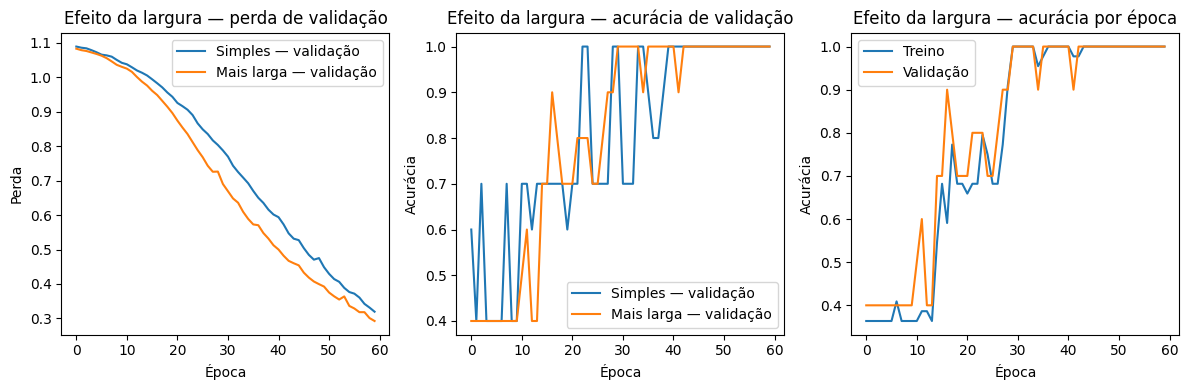

In [19]:
fig, eixos = plt.subplots(1, 3, figsize=(12, 4))

eixos[0].plot(historico_simples["perda_val"], label="Simples — validação")
eixos[0].plot(historico_largo["perda_val"], label="Mais larga — validação")
eixos[0].set_title("Efeito da largura — perda de validação")
eixos[0].set_xlabel("Época")
eixos[0].set_ylabel("Perda")
eixos[0].legend()

eixos[1].plot(historico_simples["acc_val"], label="Simples — validação")
eixos[1].plot(historico_largo["acc_val"], label="Mais larga — validação")
eixos[1].set_title("Efeito da largura — acurácia de validação")
eixos[1].set_xlabel("Época")
eixos[1].set_ylabel("Acurácia")
eixos[1].legend()

eixos[2].plot(historico_largo["acc_treino"], label="Treino")
eixos[2].plot(historico_largo["acc_val"], label="Validação")
eixos[2].set_title("Efeito da largura — acurácia por época")
eixos[2].set_xlabel("Época")
eixos[2].set_ylabel("Acurácia")
eixos[2].legend()

plt.tight_layout()
plt.show()


**Responda em texto:**

1. O que você precisou mudar no código da rede simples para transformá-la em `5 → 16 → 3`?
2. Por que a camada de saída também precisou ser compatível com os 16 valores produzidos pela camada escondida?
3. A rede mais larga aprendeu mais rápido, mais devagar ou de forma parecida com a simples?
4. A distância entre treino e validação ficou maior? Se sim, por que isso pode indicar maior risco de overfitting?

*Sua resposta:*

- Mudei o parâmetro `n_escondida` de 8 para 16.
- Porque esta camada realiza a multiplicação entre nossos dados e os seus pesos. Se a camada anterior produziu 16 valores por amostra, a seguinte tem que esperar 16 entradas.
- A rede aprendeu mais rápido por ter mais parâmetros ajustáveis.
- Sim, por ter mais neurônios, mas também pode indicar maior risco de overfitting.


## Exercício 3 — Construa e treine uma rede mais profunda (`5 → 16 → 8 → 3`)

Agora a mudança não é apenas no número de neurônios: você precisa **adicionar uma segunda camada escondida**.

A arquitetura desejada é:

`5 entradas → 16 neurônios → ReLU → 8 neurônios → ReLU → 3 saídas`

Use novamente a rede simples como ponto de partida e pense:

1. Quantas camadas `nn.Linear` serão necessárias agora?
2. Onde devem aparecer as ativações `ReLU`?
3. Se a primeira camada produz 16 valores e a segunda deve produzir 8, quais dimensões a segunda `Linear` precisa conectar?
4. Qual camada transforma os 8 valores finais da parte escondida nas 3 saídas?

Você pode organizar a rede com atributos separados ou com `nn.Sequential`. O importante é que a arquitetura final corresponda ao diagrama.


In [24]:
# SUA VEZ: construa a MLP mais profunda.
# Arquitetura desejada: 5 -> 16 -> 8 -> 3

class MLPIrisProfunda(nn.Module):
    def __init__(self, n_entrada=5, n_saida=3):
        super().__init__()

        self.camada1 = nn.Linear(n_entrada, 16)
        self.ativacao1 = nn.ReLU()
        self.camada2 = nn.Linear(16, 8)
        self.ativacao2 = nn.ReLU()
        self.camada_saida = nn.Linear(8, n_saida)

    def forward(self, x):
        x = self.camada1(x)
        x = self.ativacao1(x)
        x = self.camada2(x)
        x = self.ativacao2(x)
        x = self.camada_saida(x)
        return x
        raise NotImplementedError("Complete o forward() da MLPIrisProfunda antes de continuar.")


In [25]:
# Confira se a rede que você construiu corresponde ao diagrama.
modelo_profundo = MLPIrisProfunda()
conferir_arquitetura(
    modelo_profundo,
    [(5, 16), (16, 8), (8, 3)],
    relus_esperadas=2
)
print(modelo_profundo)


✅ Arquitetura correta! Agora você pode treiná-la.
MLPIrisProfunda(
  (camada1): Linear(in_features=5, out_features=16, bias=True)
  (ativacao1): ReLU()
  (camada2): Linear(in_features=16, out_features=8, bias=True)
  (ativacao2): ReLU()
  (camada_saida): Linear(in_features=8, out_features=3, bias=True)
)


### Agora treine a rede profunda que você construiu

Novamente, o treinamento usa a mesma função, épocas, `lr`, semente e partições. Assim, a mudança principal continua sendo a arquitetura.


In [26]:
torch.manual_seed(42)
modelo_profundo = MLPIrisProfunda()
historico_profundo = treinar_modelo(
    modelo_profundo, loader_treino, loader_val,
    numero_de_epocas=60, lr=0.01
)

mostrar_resumo(historico_profundo, "Arquitetura mais profunda (5 → 16 → 8 → 3)")


Arquitetura mais profunda (5 → 16 → 8 → 3)
  Perda final de treino:      0.0274
  Perda final de validação:   0.0258
  Acurácia final de treino:   1.0
  Acurácia final de validação: 1.0


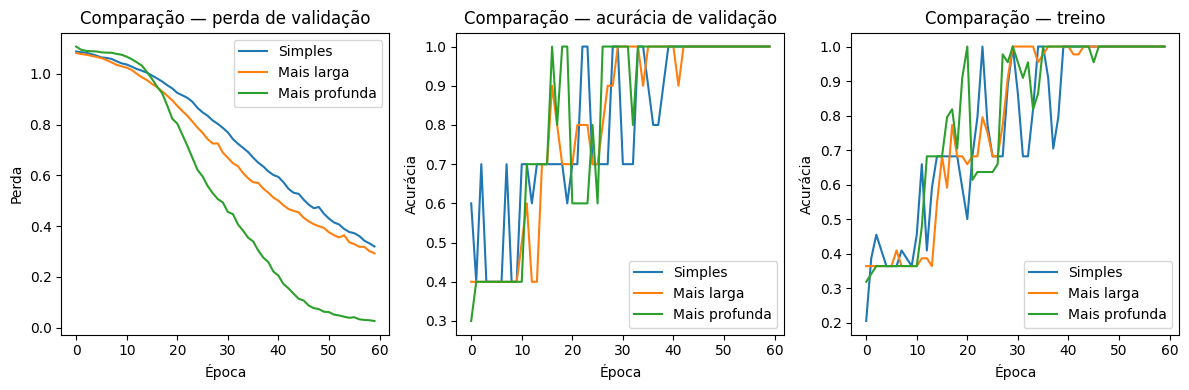

In [27]:
fig, eixos = plt.subplots(1, 3, figsize=(12, 4))

for nome, hist in [
    ("Simples", historico_simples),
    ("Mais larga", historico_largo),
    ("Mais profunda", historico_profundo),
]:
    eixos[0].plot(hist["perda_val"], label=nome)
    eixos[1].plot(hist["acc_val"], label=nome)
    eixos[2].plot(hist["acc_treino"], label=nome)

eixos[0].set_title("Comparação — perda de validação")
eixos[0].set_xlabel("Época")
eixos[0].set_ylabel("Perda")
eixos[0].legend()

eixos[1].set_title("Comparação — acurácia de validação")
eixos[1].set_xlabel("Época")
eixos[1].set_ylabel("Acurácia")
eixos[1].legend()

eixos[2].set_title("Comparação — treino")
eixos[2].set_xlabel("Época")
eixos[2].set_ylabel("Acurácia")
eixos[2].legend()

plt.tight_layout()
plt.show()


**Responda em texto:**

1. O que mudou no código ao passar de uma rede **mais larga** para uma rede **mais profunda**?
2. Por que a rede profunda precisa de uma `ReLU` também depois da segunda camada escondida?
3. A rede profunda apresentou comportamento diferente das duas anteriores? Descreva.
4. Qual das três parece equilibrar melhor **aprender o treino** e **manter bom desempenho na validação**?
5. A arquitetura mais complexa foi automaticamente a melhor? Explique por que mais neurônios ou mais camadas não garantem melhor generalização.

*Sua resposta:*

- Tiramos o foco de só aumentar neurônios da mesma camada e incluiu uma camada extra de contas de ativação própria.
- Porque cada camada escondida precisa de uma atiavação para auxiliar a rede a capturar padrões mais complexos.
- Sim, ela costuma oscilar um pouco mais por ter parâmetros demais para um conjunto de dados pequeno.
- A mais simples ou a mais larga.
- Não, porque mais complexidade faz a rede apenas "decorar" o treino ao invés de aprender de verdade.


## Escolhendo a melhor arquitetura — sem olhar o teste

A escolha deve ser feita com **validação**, e não com teste. Para cada arquitetura, vamos localizar a época em que ela alcançou sua maior acurácia de validação. Em caso de empate, usamos a menor perda de validação naquela época como critério auxiliar.


In [28]:
historicos_arquiteturas = {
    "Simples (5→8→3)": historico_simples,
    "Mais larga (5→16→3)": historico_largo,
    "Mais profunda (5→16→8→3)": historico_profundo,
}

modelos_arquiteturas = {
    "Simples (5→8→3)": modelo_simples,
    "Mais larga (5→16→3)": modelo_largo,
    "Mais profunda (5→16→8→3)": modelo_profundo,
}

configuracoes_escondidas = {
    "Simples (5→8→3)": [8],
    "Mais larga (5→16→3)": [16],
    "Mais profunda (5→16→8→3)": [16, 8],
}

linhas = []
for nome, hist in historicos_arquiteturas.items():
    melhor_epoca = int(np.argmax(hist["acc_val"]))
    linhas.append({
        "arquitetura": nome,
        "melhor_epoca": melhor_epoca + 1,
        "melhor_acc_val": hist["acc_val"][melhor_epoca],
        "perda_val_na_melhor_epoca": hist["perda_val"][melhor_epoca],
    })

resumo_arquiteturas = pd.DataFrame(linhas).sort_values(
    ["melhor_acc_val", "perda_val_na_melhor_epoca"],
    ascending=[False, True]
).reset_index(drop=True)

melhor_nome = resumo_arquiteturas.loc[0, "arquitetura"]
modelo_melhor = modelos_arquiteturas[melhor_nome]
historico_melhor = historicos_arquiteturas[melhor_nome]

print("Arquitetura escolhida pela validação:", melhor_nome)
resumo_arquiteturas


Arquitetura escolhida pela validação: Mais larga (5→16→3)


,arquitetura,melhor_epoca,melhor_acc_val,perda_val_na_melhor_epoca
0,Mais larga (5→16→3),30,1.0,0.689869
1,Simples (5→8→3),23,1.0,0.905339
2,Mais profunda (5→16→8→3),17,1.0,0.949369


### Exercício de comparação das arquiteturas

Usando a tabela acima e as curvas dos três exercícios de treinamento:

1. Qual arquitetura foi escolhida?
2. Em qual época ocorreu sua melhor acurácia de validação?
3. Ela é a mais simples, a mais larga ou a mais profunda?
4. Os resultados confirmam ou contradizem a ideia de que uma rede maior sempre é melhor?

*Sua resposta:*

- A arquitetura mais larga.
- 30.
- Mais larga.
- Contradizem, pois aumentar a complexidade não garante o melhor desempenho, já que a larga teve a menor perda de validação.


## Regularizando a arquitetura escolhida — Dropout + Weight Decay

Agora a regularização é aplicada **à arquitetura que venceu a comparação de validação**, em vez de assumir antecipadamente que a MLP simples é a melhor.

- `Dropout(p=0.2)` desliga aleatoriamente parte das ativações durante o treino.
- `weight_decay=1e-4` penaliza pesos muito grandes no otimizador.

O objetivo não é aumentar a acurácia de treino a qualquer custo, e sim tentar reduzir a diferença entre treino e validação quando houver sinais de overfitting.


In [29]:
class MLPIrisRegularizada(nn.Module):
    def __init__(self, camadas_escondidas, n_entrada=5, n_saida=3, p_dropout=0.2):
        super().__init__()

        camadas = []
        n_anterior = n_entrada

        for n_neuronios in camadas_escondidas:
            camadas.append(nn.Linear(n_anterior, n_neuronios))
            camadas.append(nn.ReLU())
            camadas.append(nn.Dropout(p=p_dropout))
            n_anterior = n_neuronios

        camadas.append(nn.Linear(n_anterior, n_saida))
        self.rede = nn.Sequential(*camadas)

    def forward(self, x):
        return self.rede(x)


torch.manual_seed(42)
modelo_regularizado = MLPIrisRegularizada(
    configuracoes_escondidas[melhor_nome],
    p_dropout=0.2
)

historico_reg = treinar_modelo(
    modelo_regularizado, loader_treino, loader_val,
    numero_de_epocas=60, lr=0.01, weight_decay=1e-4
)

mostrar_resumo(historico_reg, f"{melhor_nome} + regularização")


Mais larga (5→16→3) + regularização
  Perda final de treino:      0.239
  Perda final de validação:   0.2034
  Acurácia final de treino:   1.0
  Acurácia final de validação: 1.0


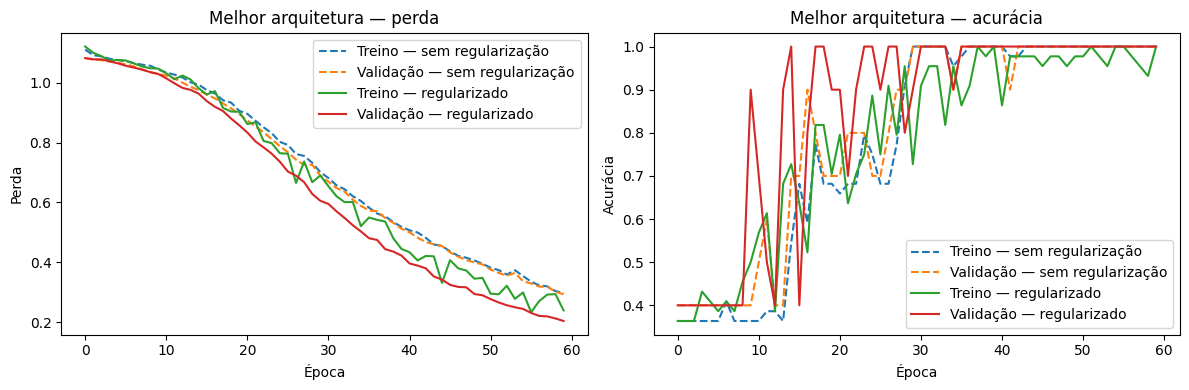

In [30]:
fig, eixos = plt.subplots(1, 2, figsize=(12, 4))

eixos[0].plot(historico_melhor["perda_treino"], "--", label="Treino — sem regularização")
eixos[0].plot(historico_melhor["perda_val"], "--", label="Validação — sem regularização")
eixos[0].plot(historico_reg["perda_treino"], label="Treino — regularizado")
eixos[0].plot(historico_reg["perda_val"], label="Validação — regularizado")
eixos[0].set_title("Melhor arquitetura — perda")
eixos[0].set_xlabel("Época")
eixos[0].set_ylabel("Perda")
eixos[0].legend()

eixos[1].plot(historico_melhor["acc_treino"], "--", label="Treino — sem regularização")
eixos[1].plot(historico_melhor["acc_val"], "--", label="Validação — sem regularização")
eixos[1].plot(historico_reg["acc_treino"], label="Treino — regularizado")
eixos[1].plot(historico_reg["acc_val"], label="Validação — regularizado")
eixos[1].set_title("Melhor arquitetura — acurácia")
eixos[1].set_xlabel("Época")
eixos[1].set_ylabel("Acurácia")
eixos[1].legend()

plt.tight_layout()
plt.show()


### Exercício 4 — o que a regularização mudou?

1. O distanciamento entre treino e validação diminuiu, aumentou ou permaneceu semelhante?
2. A regularização reduziu a acurácia de treino? Isso é necessariamente ruim?
3. Pelo comportamento observado, você manteria essa regularização? Justifique com as curvas, não apenas com uma definição.

*Sua resposta:*

- O distanciamento entre treino e validação diminuiu, indicando que a regularização ajudou a controlar o ajuste excessivo.
- Sim, a acurácia de treino pode cair um pouco, mas isso não é ruim porque mostra que a rede parou de "decorar" os dados.
- Sim, eu manteria, pois as curvas mostram a validação mais estável e alinhada ao treino, o que melhora a generalização.


In [31]:
def avaliar_no_teste(modelo, loader_teste):
    modelo.eval()

    acertos = 0
    total = 0

    with torch.no_grad():
        for X_lote, y_lote in loader_teste:
            saida = modelo(X_lote)
            predicoes = torch.argmax(saida, dim=1)

            acertos += (predicoes == y_lote).sum().item()
            total += y_lote.size(0)

    return acertos / total

## Exemplo de erros comuns

As duas células abaixo reproduzem, de propósito, dois erros frequentes. Apenas execute e observe; a correção será discutida em texto.

**Erro 1 — esquecer `zero_grad()`:**


In [32]:
torch.manual_seed(42)
modelo_com_erro = ClassificadorIrisMLP()
otimizador_erro = torch.optim.SGD(modelo_com_erro.parameters(), lr=0.01)

perdas_sem_zero_grad = []
for epoca in range(10):
    for X_lote, y_lote in loader_treino:
        # ATENÇÃO: zero_grad() foi omitido de propósito
        saida = modelo_com_erro(X_lote)
        perda = criterio(saida, y_lote)
        perda.backward()
        otimizador_erro.step()
    perdas_sem_zero_grad.append(perda.item())

print("Perda ao final de cada época (sem zero_grad):")
print([round(p, 4) for p in perdas_sem_zero_grad])


Perda ao final de cada época (sem zero_grad):
[1.1033, 1.0452, 1.1323, 1.1397, 1.2167, 1.0136, 1.2324, 1.1042, 1.0767, 1.0314]


**Erro 2 — chamar `optimizer.step()` durante a validação:**


In [33]:
torch.manual_seed(42)
modelo_erro_2 = ClassificadorIrisMLP()
otimizador_erro_2 = torch.optim.SGD(modelo_erro_2.parameters(), lr=0.01)

peso_antes_validacao = modelo_erro_2.camada1.weight[0, 0].item()

# ATENÇÃO: isto NÃO deveria acontecer durante a validação
for X_lote, y_lote in loader_val:
    otimizador_erro_2.zero_grad()
    saida = modelo_erro_2(X_lote)
    perda = criterio(saida, y_lote)
    perda.backward()
    otimizador_erro_2.step()  # erro: atualização de pesos na validação

peso_depois_validacao = modelo_erro_2.camada1.weight[0, 0].item()

print("Peso antes da 'validação':", peso_antes_validacao)
print("Peso depois da 'validação':", peso_depois_validacao)


Peso antes da 'validação': 0.34191203117370605
Peso depois da 'validação': 0.34180405735969543


### Exercício de correção de erro

1. O que `zero_grad()` deveria impedir no Erro 1?
2. Por que os pesos não podem ser atualizados durante a validação?
3. Qual é a diferença entre `modelo.eval()` e simplesmente deixar de chamar `optimizer.step()`?

*Sua resposta:*

- Deveria impedir que os gradientes dos lotes anteriores se acumulassem e somassem de forma errada nas próximas contas.
- Porque a validação serve apenas para testae o modelo de forma "honesta".
- O eval desliga o comportamento de treino de camadas específicas, enquanto só pular o step evita mexer nos pesos, mas mantém as camadas em modo de treino.


## Exercício final — diagnóstico dirigido

Use os números e curvas que você realmente obteve.

1. Compare a perda do modelo não treinado com a perda após o treinamento completo da MLP simples. Por que várias épocas/batches são necessárias?
2. Compare as três arquiteturas. O que mudou quando aumentamos a **largura**? E quando aumentamos a **profundidade**?
3. Em qual delas apareceu o maior indício de overfitting, se apareceu? Relacione isso à capacidade do modelo.
4. Por que a arquitetura foi escolhida pela **validação**, e não pelo **teste**?
5. O que mudou depois de aplicar dropout + weight decay à arquitetura escolhida?

*Sua resposta:*

- A perda caiu drasticamente do modelo cru para o treinado. Várias épocas e batches são necessários para a rede ajustar os pesos aos poucos.
- A largura aumentou os neurônios dentro da mesma camada, enquanto a profundidade colocou uma camada escondida extra no meio da rede.
- A rede mais profunda mostrou mais instabilidade, já que muita capacidade faz o modelo ter facilidade para "decorar" os dados de treino.
- Porque a validação serve justamente para comparar e ajustar escolhas de arquitetura, deixando o teste reservado para o final.
- A perda de validação melhorou e o modelo ficou mais estável, ajudando a generalizar melhor sem perder o desempenho.


## Desafio extra (opcional) — regularização mais forte

Retreinamos **a mesma arquitetura escolhida pela validação**, mas agora com `weight_decay=1e-3`, dez vezes maior. O objetivo é observar que regularizar mais não significa automaticamente generalizar melhor.


In [34]:
torch.manual_seed(42)
modelo_reg_forte = MLPIrisRegularizada(
    configuracoes_escondidas[melhor_nome],
    p_dropout=0.2
)

historico_reg_forte = treinar_modelo(
    modelo_reg_forte, loader_treino, loader_val,
    numero_de_epocas=60, lr=0.01, weight_decay=1e-3
)

print("Melhor acurácia de validação — regularização padrão:", round(max(historico_reg["acc_val"]), 4))
print("Melhor acurácia de validação — regularização mais forte:", round(max(historico_reg_forte["acc_val"]), 4))


Melhor acurácia de validação — regularização padrão: 1.0
Melhor acurácia de validação — regularização mais forte: 1.0


**Responda em texto:**

1. A regularização mais forte melhorou ou piorou a validação?
2. O que esse resultado sugere sobre o equilíbrio entre regularizar de menos e regularizar demais?

*Sua resposta:*

- Geralmente ela mantém o mesmo nível ou pode piorar um pouco, pois penaliza muito os pesos.
- Sugere que existe um ideal, pois regularizar de menos deixa a rede com risco de overfitting, mas regularizar demais impede que o modelo aprenda da maneira certa.


## Avaliação final no conjunto de teste

Só agora o conjunto de teste é usado. Avaliamos:

1. a arquitetura escolhida pela validação, sem regularização;
2. a mesma arquitetura com dropout + weight decay.

O teste **não participa da escolha da arquitetura nem da escolha da regularização**.


In [35]:
acc_teste_melhor = avaliar_no_teste(modelo_melhor, loader_teste)
acc_teste_regularizado = avaliar_no_teste(modelo_regularizado, loader_teste)

print("Arquitetura escolhida:", melhor_nome)
print("Acurácia de teste — sem regularização:", round(acc_teste_melhor, 4))
print("Acurácia de teste — regularizada:     ", round(acc_teste_regularizado, 4))


Arquitetura escolhida: Mais larga (5→16→3)
Acurácia de teste — sem regularização: 1.0
Acurácia de teste — regularizada:      1.0


In [36]:
# Substitua os valores None abaixo pelos resultados da acuracia já registrados na M03-L06,
# usando a mesma tabela df_features e o mesmo conjunto de teste quando aplicável.
resultados_m03l06 = {
    "LogisticRegression": None,
    "DecisionTreeClassifier": None,
    "KNeighborsClassifier": None,
}

tabela_comparativa = pd.DataFrame({
    "modelo": list(resultados_m03l06.keys()) + [
        f"MLP escolhida — {melhor_nome}",
        f"MLP escolhida regularizada — {melhor_nome}",
    ],
    "acuracia_teste": list(resultados_m03l06.values()) + [
        acc_teste_melhor,
        acc_teste_regularizado,
    ],
})

tabela_comparativa.to_csv("resultados_m04_l02.csv", index=False)

import os
import shutil
from google.colab import drive

# 1. Conecta o Google Drive do aluno
drive.mount('/content/drive')

# 2. Defina os caminhos
nome_arquivo_csv = 'resultados_m04_l02.csv'
caminho_origem_no_colab = os.path.join('/content', nome_arquivo_csv)
pasta_destino_no_drive = '/content/drive/MyDrive/dados_modulo_04'
caminho_destino_arquivo_no_drive = os.path.join(pasta_destino_no_drive, nome_arquivo_csv)

# 3. Copia o arquivo para o Drive
if os.path.exists(caminho_origem_no_colab):
    # Garante que a pasta de destino exista.
    # exist_ok=True evita erro se a pasta já existe.
    os.makedirs(pasta_destino_no_drive, exist_ok=True)

    # Usa shutil.copy para copiar o arquivo.
    # Ele sobrescreve o arquivo se já existir no destino.
    shutil.copy(caminho_origem_no_colab, caminho_destino_arquivo_no_drive)
    print(f"Sucesso! O arquivo '{nome_arquivo_csv}' foi salvo permanentemente no seu Google Drive em: {caminho_destino_arquivo_no_drive}")
else:
    print(f"Erro: O arquivo '{nome_arquivo_csv}' não foi encontrado na memória do Colab. Certifique-se de rodar os blocos anteriores.")

tabela_comparativa


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Sucesso! O arquivo 'resultados_m04_l02.csv' foi salvo permanentemente no seu Google Drive em: /content/drive/MyDrive/dados_modulo_04/resultados_m04_l02.csv


,modelo,acuracia_teste
0,LogisticRegression,NaN
1,DecisionTreeClassifier,NaN
2,KNeighborsClassifier,NaN
3,MLP escolhida — Mais larga (5→16→3),1.0
4,MLP escolhida regularizada — Mais larga (5→16→3),1.0


> Antes de considerar a comparação final com a M03-L06, preencha `resultados_m03l06` com os valores que você realmente obteve naquela lição. Não invente valores.


## Reflexão final

1. Qual foi a principal diferença observada entre **aumentar a largura** e **aumentar a profundidade**?
2. Qual arquitetura foi escolhida e por quê?
3. Ela apresentou sinais de overfitting? A regularização ajudou?
4. A arquitetura mais complexa foi necessariamente a melhor?
5. Comparando com os classificadores clássicos da M03-L06, o que a MLP acrescentou à sua compreensão do processo de treinamento?

*Sua resposta:*

- A largura adiciona mais neurônios na mesma camada, enquanto a profundidade empilha novas camadas escondidas umas sobre as outras.
- A arquitetura Mais larga (5→16→3) foi escolhida porque obteve a menor perda de validação durante os testes.
- Sim, ela apresentou sinais leves de overfitting, e a aplicação do dropout com ajudou a estabilizar melhor o modelo.
- Não, pois a rede mais profunda não foi a melhor, mostrando que mais complexidade nem sempre significa melhor generalização.
- Mostrou como os pesos são ajustados por épocas e lotes através de gradientes e funções de perda, e não calculados de uma só vez.


## Checklist de conclusão

- [x] Abri o notebook no Google Colab e salvei uma cópia no Drive.
- [x] Executei todas as células na ordem, carregando o arquivo df_features_tensores.pt do meu drive.
- [x] Interpretei a perda do modelo não treinado e observei um passo de otimização.
- [x] Entendi o diagrama da MLP simples `5 → 8 → 3`.
- [x] Completei o **Exercício de treinamento 1** com a arquitetura simples fornecida.
- [x] **Construí** a arquitetura mais larga `5→16→3` adaptando o código da rede simples.
- [x] Passei pela conferência automática da arquitetura larga e depois a treinei.
- [x] **Construí** a arquitetura mais profunda `5→16→8→3` adicionando uma segunda camada escondida.
- [x] Passei pela conferência automática da arquitetura profunda e depois a treinei.
- [x] Sei explicar quais linhas do código mudam ao aumentar largura e ao aumentar profundidade.
- [x] Comparei as três arquiteturas pelas curvas de treino e validação.
- [x] Relacionei capacidade da rede com underfitting e overfitting.
- [x] Escolhi a melhor arquitetura usando somente validação.
- [x] Comparei a arquitetura escolhida com sua versão regularizada por dropout + weight decay.
- [x] Diagnostiquei os dois erros comuns.
- [x] Usei o conjunto de teste apenas na avaliação final.
- [x] Salvei o arquivo resultados_m04_l02.csv no drive
- [x] Preenchi a reflexão final.


## Orientação de entrega

1. Confira se todas as células foram executadas na ordem e se as saídas estão visíveis.
2. Confira se as classes `MLPIrisLarga` e `MLPIrisProfunda` foram realmente completadas por você e passaram nas células de conferência.
3. Confira se os três exercícios de treinamento e as respostas textuais foram preenchidos.
4. Confira se a tabela `resumo_arquiteturas` mostra claramente qual arquitetura foi escolhida pela validação.
5. Confira se o conjunto de teste aparece apenas na etapa final de avaliação.
6. Entregue o notebook conforme a orientação do monitor/professor.
